# Experimental protocol and selected parameters


In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("tuned")


## Workflow


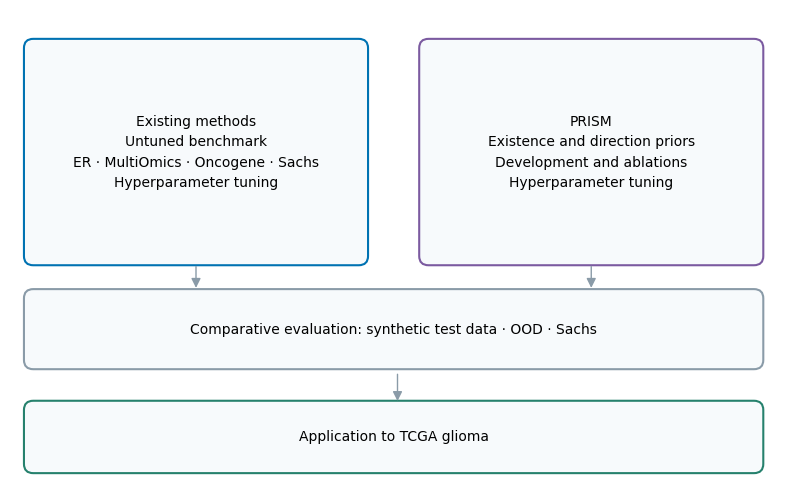

In [2]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(10, 6.2))
ax.set(xlim=(0, 10), ylim=(0, 6.2))
ax.axis("off")
def box(x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.12", facecolor="#F7FAFC", edgecolor=color, linewidth=1.5))
    ax.text(x+w/2, y+h/2, text, ha="center", va="center", fontsize=10, linespacing=1.6)
box(.3, 3, 4.2, 2.7, "Existing methods\nUntuned benchmark\nER · MultiOmics · Oncogene · Sachs\nHyperparameter tuning", "#0072B2")
box(5.4, 3, 4.2, 2.7, "PRISM\nExistence and direction priors\nDevelopment and ablations\nHyperparameter tuning", "#7B5AA0")
box(.3, 1.65, 9.3, .8, "Comparative evaluation: synthetic test data · OOD · Sachs", "#8A9BA8")
box(.3, .3, 9.3, .7, "Application to TCGA glioma", "#26816D")
for x in (2.4, 7.5):ax.annotate("", xy=(x, 2.55), xytext=(x, 2.9), arrowprops=dict(arrowstyle="-|>", color="#8A9BA8"))
ax.annotate("", xy=(5, 1.08), xytext=(5, 1.5), arrowprops=dict(arrowstyle="-|>", color="#8A9BA8"))
th.save_pdf(fig, "experimental_workflow.pdf")
display(fig)
plt.close(fig)


## Search spaces

Positive continuous parameters use logarithmic sampling unless the configuration declares a linear range. AVICI has no fitting hyperparameters; its threshold is selected using validation data.


In [3]:
baseline = json.loads((ROOT / "configs/baseline_study.json").read_text())
rows = []
for model, space in baseline["spaces"].items():
    if not space:
        fixed = baseline["defaults"][model] or {"pretrained": "scm-v0"}
        for parameter, value in fixed.items():
            rows.append(dict(model=model, trials=baseline["trials"][model], parameter=parameter,
                             default=value, search=json.dumps([value]), sampling="fixed"))
    for parameter, definition in space.items():
        options = definition.get("choices", [definition.get("low"), definition.get("high")])
        rows.append(dict(model=model, trials=baseline["trials"][model], parameter=parameter,
                         default=baseline["defaults"][model].get(parameter),
                         search=json.dumps(options), sampling=definition["type"]))
spaces = pd.DataFrame(rows)
display(spaces)


,model,trials,parameter,default,search,sampling
0,PC,24,alpha,0.05,"[0.005, 0.5]",float_log
1,PC,24,indep_test,fisherz,"[""fisherz"", ""rcit""]",categorical
2,PC,24,uc_rule,0,"[0, 1, 2]",categorical
3,FCI,32,alpha,0.05,"[0.005, 0.5]",float_log
4,FCI,32,independence_test_method,fisherz,"[""fisherz"", ""rcit""]",categorical
5,FCI,32,depth,-1,"[-1, 2, 3, 4]",categorical
6,FCI,32,max_path_length,-1,"[-1, 3, 5]",categorical
7,GES,16,lambda_value,1.0,"[0.25, 8.0]",float_log
8,GES,16,maxP,None,"[null, 3, 5]",categorical
9,GRaSP,16,depth,3,"[1, 2, 3, 4]",categorical


## Selected model configurations


In [4]:
winners = json.loads((ROOT / "configs/frozen/frozen_winners.json").read_text())["winners"]
prism = json.loads((ROOT / "configs/prism_winner.json").read_text())
rows = [dict(model=model, threshold=winner.get("threshold"),
             parameters=json.dumps(winner["params"], sort_keys=True)) for model, winner in winners.items()]
rows.append(dict(model="PRISM", threshold=prism["threshold"], parameters=json.dumps(prism["params"], sort_keys=True)))
selected = pd.DataFrame(rows)
display(selected)


,model,threshold,parameters
0,AVICI,0.70,{}
1,DAGMA_Linear,0.10,"{""T"": 6, ""lambda1"": 0.10055892387592255, ""lr"":..."
2,DAGMA_Nonlinear,0.80,"{""T"": 6, ""hidden_dim"": 8, ""iter_scale"": 0.0625..."
3,DAS,NaN,"{""alpha"": 0.005233625874486607, ""das_cutoff"": ..."
4,DirectLiNGAM,0.15,"{""measure"": ""pwling""}"
5,FCI,NaN,"{""alpha"": 0.22583751255202858, ""depth"": 4, ""in..."
6,GES,NaN,"{""lambda_value"": 2.382429027868342, ""maxP"": nu..."
7,GOLEM,0.15,"{""equal_variances"": false, ""lambda_1"": 0.03870..."
8,GRaSP,NaN,"{""depth"": 3, ""lambda_value"": 2.0, ""score_func""..."
9,GraNDAG,NaN,"{""hidden_dim"": 10, ""hidden_num"": 1, ""lr"": 0.00..."
